# Industry Life Cycles and Competitive Structure: Concentration and Margins by Industry from SEC Filings, Cash-Flow Life-Cycle Stages with a Gradient-Boosting Forecast, and Text-Based Peers from 10-K Business Descriptions

Industry analysis in the CFA curriculum rests on two frameworks: the **industry life cycle** (embryonic, growth, shakeout, mature, decline) and **Porter's five forces**, of which concentration, barriers to entry and rivalry are the measurable ones. Both are usually taught qualitatively. This notebook measures them for every U.S. listed non-financial company that files XBRL, 2010–2025:

1. **Competitive structure by industry** (SIC three-digit codes): number of firms, the Herfindahl–Hirschman index (HHI) and four-firm concentration ratio (CR4) of revenue, margins, growth, R&D and capital intensity, entry and exit.
2. **Life-cycle stages of firms** from the signs of operating, investing and financing cash flows (Dickinson, 2011), and a **LightGBM forecast** of which stage a company will be in next year, against the naive forecast that it stays where it is.
3. **Do concentrated industries earn more?** Margins against concentration, and how fast unusually high or low profitability fades (Fama and French, 2000), by concentration level.
4. **Clustering industries into life-cycle groups** with k-means and Gaussian mixtures on their growth, margins, investment, concentration, entry, exit and stage mix.
5. **Text-based industries** (Hoberg and Phillips, 2016): S&P 500 companies' 10-K business descriptions embedded with a sentence-transformer, nearest peers by cosine similarity, compared with SIC codes and GICS sectors by how well each peer group explains a company's stock returns.

**Data.** SEC XBRL frames API (revenue, operating income, assets, cash flows, R&D, capital expenditure, dividends, 2010–2025); SEC Financial Statement Data Sets (SIC codes of filers); SEC SIC code list; SEC EDGAR (latest 10-K of S&P 500 members); iShares Core S&P 500 ETF holdings (members and GICS sectors); Yahoo Finance (weekly prices).

**Methods.** HHI and CR4, Dickinson life-cycle classification, panel regressions with clustered errors, partial-adjustment models of profitability, LightGBM and multinomial logistic classification, k-means, Gaussian mixtures, silhouette scores, PCA, sentence embeddings (all-MiniLM-L6-v2), cosine-similarity peers, adjusted Rand index.

**Key output.** Concentration and life-cycle profiles of U.S. industries; whether concentration goes with higher and more persistent margins; how well next year's life-cycle stage can be predicted; and whether text-based peers beat SIC codes and GICS sectors.

## 1. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import html as htmllib
import io
import zipfile
import lightgbm as lgb
import statsmodels.formula.api as smf
import yfinance as yf
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    adjusted_rand_score,
    f1_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2026
SEC_HEADERS = {"User-Agent": os.getenv("SEC_USER_AGENT", "").strip()}
if not SEC_HEADERS["User-Agent"]:
    raise RuntimeError(
        "SEC_USER_AGENT missing in .env (the SEC asks automated clients to"
        " identify themselves)."
    )
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}
IVV_URL = "https://www.ishares.com/us/products/239726/fund/latest-holdings.csv"
FIRST_CY, LAST_CY = 2010, 2025
# SIC codes of filers over time
SIC_QUARTERS = ["2012q1", "2015q1", "2018q1", "2021q1", "2024q1", "2026q3"]
CONCEPTS = {
    "rev": (
        [
            "Revenues",
            "RevenueFromContractWithCustomerExcludingAssessedTax",
            "SalesRevenueNet",
        ],
        "USD",
        "",
    ),
    "opinc": (["OperatingIncomeLoss"], "USD", ""),
    "assets": (["Assets"], "USD", "Q4I"),
    "cfo": (["NetCashProvidedByUsedInOperatingActivities"], "USD", ""),
    "cfi": (["NetCashProvidedByUsedInInvestingActivities"], "USD", ""),
    "cff": (["NetCashProvidedByUsedInFinancingActivities"], "USD", ""),
    "rd": (["ResearchAndDevelopmentExpense"], "USD", ""),
    "capex": (["PaymentsToAcquirePropertyPlantAndEquipment"], "USD", ""),
    "div": (
        ["PaymentsOfDividends", "PaymentsOfDividendsCommonStock"],
        "USD",
        "",
    ),
}
MIN_REV = 10e6  # firms with at least USD 10 million of revenue
# industries with at least eight such firms in a year
MIN_FIRMS = 8
# stage-transition model: trained on transitions up to 2019→2020
TRAIN_LAST = 2019
TEXT_MAX_CHARS = 1_500_000
N_PEERS = 10

print(
    f"lightgbm {lgb.__version__} · yfinance {yf.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · yfinance 1.7.0 · run on 2026-11-18


In [2]:
# --- Round only the numeric columns (dates and text are left as they are)
def round_num(df, n=2):
    num = df.select_dtypes("number").columns
    return df.assign(**{c: df[c].round(n) for c in num})


# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 2. Data

Annual values from the XBRL frames API (one value per company and calendar year, the fiscal year closest to it), SIC codes from the SEC's Financial Statement Data Sets (the latest code seen for each company), and the SEC's list of SIC industry titles. Financial companies (SIC 6000–6799) are excluded, because revenue, margins and cash-flow signs mean something different for them.

In [3]:
def sec_get(url, timeout=120):
    for attempt in range(4):
        r = requests.get(url, headers=SEC_HEADERS, timeout=timeout)
        if r.status_code == 200:
            return r
        if r.status_code == 404:
            return None
        time.sleep(2 + 3 * attempt)
    r.raise_for_status()


def fetch_frames():
    out = []
    for item, (tags, unit, sfx) in CONCEPTS.items():
        for rank, tag in enumerate(tags):
            for cy in range(FIRST_CY - 1, LAST_CY + 1):
                r = sec_get(
                    f"https://data.sec.gov/api/xbrl/frames/us-gaap/{tag}/{unit}/CY{cy}{sfx}.json"
                )
                if r is None:
                    continue
                out.append(
                    pd.DataFrame(r.json()["data"])[
                        ["cik", "entityName", "val"]
                    ].assign(item=item, cy=cy, rank=rank)
                )
                time.sleep(0.12)
    return pd.concat(out, ignore_index=True)


def fetch_sic():
    out = []
    for q in SIC_QUARTERS:
        z = zipfile.ZipFile(
            io.BytesIO(
                sec_get(
                    f"https://www.sec.gov/files/dera/data/financial-statement-data-sets/{q}.zip",
                    timeout=600,
                ).content
            )
        )
        out.append(
            pd.read_csv(
                z.open("sub.txt"), sep="\t", dtype=str, usecols=["cik", "sic"]
            )
            .dropna()
            .assign(q=q)
        )
    return pd.concat(out, ignore_index=True)


def fetch_sic_titles():
    r = sec_get(
        "https://www.sec.gov/search-filings/standard-industrial-classification-sic-code-list"
    )
    t = pd.read_html(io.StringIO(r.text))[0]
    t.columns = t.iloc[0]
    return t.iloc[1:][["SIC Code", "Industry Title"]].astype(str)


FR = cached("sec_frames_industry", fetch_frames, max_age_hours=24 * 14)
SICR = cached("sec_fsds_sic_codes", fetch_sic, max_age_hours=24 * 90)
TITLES = cached("sec_sic_titles", fetch_sic_titles, max_age_hours=24 * 365)
SIC = (
    SICR.sort_values("q")
    .drop_duplicates("cik", keep="last")
    .astype({"cik": int, "sic": int})
    .set_index("cik")
    .sic
)
title4 = dict(
    zip(TITLES["SIC Code"].astype(int), TITLES["Industry Title"].str.title())
)
FR = FR.sort_values("rank").drop_duplicates(["cik", "item", "cy"])
names = FR.drop_duplicates("cik", keep="last").set_index("cik").entityName
F = FR.pivot_table(
    index=["cik", "cy"], columns="item", values="val"
).reset_index()
F["sic"] = F.cik.map(SIC)
F = F[F.sic.notna() & ~F.sic.between(6000, 6799)].copy()
F["sic3"] = (F.sic // 10).astype(int)
F = F.sort_values(["cik", "cy"])
F["rev_lag"] = (
    F.groupby("cik").rev.shift(1).where(F.groupby("cik").cy.diff() == 1)
)
F = F[F.cy >= FIRST_CY]
print(
    f"{F.cik.nunique():,} non-financial companies with an SIC code ·"
    f" {len(F):,} company-years {FIRST_CY}–{LAST_CY}"
)

9,330 non-financial companies with an SIC code · 80,801 company-years 2010–2025


In [4]:
def sic3_title(s3):
    for code_ in range(s3 * 10, s3 * 10 + 10):
        if code_ in title4:
            return title4[code_]
    return f"SIC {s3}"


F["growth"] = (F.rev / F.rev_lag - 1).where(F.rev_lag > 0).clip(-0.9, 3)
F["margin"] = (F.opinc / F.rev).where(F.rev > 0).clip(-1, 1)
F["roa"] = (F.opinc / F.assets).where(F.assets > 0).clip(-1, 1)
F["rd_int"] = (F.rd.fillna(0) / F.rev).where(F.rev > 0).clip(0, 2)
F["capex_int"] = (F.capex / F.rev).where(F.rev > 0).clip(0, 2)
F["payer"] = (F["div"].fillna(0) > 0).astype(int)


# Dickinson (2011): life-cycle stage from the signs of operating, investing and
# financing cash flows
def stage(cfo, cfi, cff):
    if pd.isna(cfo) or pd.isna(cfi) or pd.isna(cff):
        return np.nan
    if cfo < 0 and cfi < 0 and cff > 0:
        return "introduction"
    if cfo > 0 and cfi < 0 and cff > 0:
        return "growth"
    if cfo > 0 and cfi < 0 and cff < 0:
        return "mature"
    if cfo < 0 and cfi > 0:
        return "decline"
    return "shake-out"


STAGES = ["introduction", "growth", "mature", "shake-out", "decline"]
F["stage"] = [stage(a, b, c) for a, b, c in zip(F.cfo, F.cfi, F.cff)]
first = F.groupby("cik").cy.transform("min")
last = F.groupby("cik").cy.transform("max")
F["entry"] = ((F.cy == first) & (F.cy > FIRST_CY)).astype(int)
F["exit"] = ((F.cy == last) & (F.cy < LAST_CY - 1)).astype(int)
F["age"] = F.cy - first
FF = F[F.rev >= MIN_REV].copy()
print("Life-cycle stages, all company-years (%):")
(FF.stage.value_counts(normalize=True).reindex(STAGES) * 100).round(1)

Life-cycle stages, all company-years (%):


stage
introduction   13.70
growth         24.60
mature         46.00
shake-out       9.80
decline         5.80
Name: proportion, dtype: float64

## 3. Competitive structure by industry

For each SIC three-digit industry and year with at least eight companies of USD 10 million or more in revenue:

- **HHI** = $10{,}000 \times \sum_i s_i^2$, where $s_i$ is company $i$'s share of industry revenue. U.S. merger guidelines call a market *highly concentrated* above 1,800 (2023 Merger Guidelines; 2,500 in the 2010 version).
- **CR4** = the combined share of the four largest companies.
- **Aggregate operating margin** = industry operating income ÷ industry revenue; median revenue growth; R&D and capital expenditure as a share of revenue.
- **Entry and exit rates:** the share of companies appearing for the first time, or for the last time, in the XBRL data that year. This captures listings, delistings, mergers and bankruptcies of public companies, not private entrants.

These are measures of *listed* companies classified by their main SIC code. Private competitors, imports and multi-industry conglomerates make true market concentration different, which is a reason to read HHI levels as relative rather than absolute.

In [5]:
def industry_year(g):
    s = g.rev / g.rev.sum()
    st = g.stage.value_counts(normalize=True)
    return pd.Series({
        "firms": len(g),
        "HHI": 1e4 * (s**2).sum(),
        "CR4": s.nlargest(4).sum(),
        "revenue_bn": g.rev.sum() / 1e9,
        "margin": (
            g.opinc.sum() / g.rev[g.opinc.notna()].sum()
            if g.opinc.notna().any()
            else np.nan
        ),
        "growth": g.growth.median(),
        "rd_int": g.rd.fillna(0).sum() / g.rev.sum(),
        "capex_int": (
            g.capex.sum() / g.rev[g.capex.notna()].sum()
            if g.capex.notna().any()
            else np.nan
        ),
        "entry": g.entry.mean(),
        "exit": g.exit.mean(),
        "payers": g.payer.mean(),
        **{f"stage_{k}": st.get(k, 0.0) for k in STAGES},
    })


IY = (
    FF.groupby(["sic3", "cy"])
    .apply(industry_year, include_groups=False)
    .reset_index()
)
IY = IY[IY.firms >= MIN_FIRMS].copy()
IY["industry"] = IY.sic3.map(sic3_title)
lat = (
    IY[IY.cy.between(LAST_CY - 4, LAST_CY - 1)]
    .groupby(["sic3", "industry"])
    .mean(numeric_only=True)
    .drop(columns="cy")
    .reset_index()
)
lat = lat[lat.firms >= MIN_FIRMS]
print(
    f"{IY.sic3.nunique()} industries with at least {MIN_FIRMS} companies in"
    f" some year; {len(lat)} in {LAST_CY - 4}–{LAST_CY - 1} (averages below)"
)
cols = [
    "industry",
    "firms",
    "HHI",
    "CR4",
    "margin",
    "growth",
    "rd_int",
    "capex_int",
    "entry",
    "exit",
]
print("Most concentrated industries")
display(lat.nlargest(10, "HHI")[cols].round(3))
print("Least concentrated industries")
display(lat.nsmallest(10, "HHI")[cols].round(3))
agg = IY.groupby("cy").apply(
    lambda g: pd.Series({
        "median HHI": g.HHI.median(),
        "share above 1,800": (g.HHI > 1800).mean(),
        "median firms": g.firms.median(),
    }),
    include_groups=False,
)
agg.round(2)

116 industries with at least 8 companies in some year; 99 in 2021–2024 (averages below)
Most concentrated industries


,industry,firms,HHI,CR4,margin,growth,rd_int,capex_int,entry,exit
1,Gold And Silver Ores,8.50,"8,429.46",0.99,-0.18,0.09,0.01,0.13,0.06,0.00
76,Retail-Nonstore Retailers,26.25,"6,966.57",0.92,0.05,0.05,0.00,0.02,0.03,0.04
88,Services-Miscellaneous Amusement & Recreation,23.25,"6,320.66",0.88,0.13,0.24,0.00,0.06,0.05,0.02
28,Engines & Turbines,8.00,"5,998.31",0.98,0.09,0.03,0.04,0.04,0.00,0.04
46,Trucking & Courier Services (No Air),12.00,"5,587.67",0.89,0.11,0.08,0.00,0.06,0.02,0.02
45,Miscellaneous Manufacturing Industries,9.25,"5,197.74",0.95,0.09,0.10,0.01,0.04,0.03,0.05
27,Miscellaneous Fabricated Metal Products,10.00,"4,490.21",0.89,0.16,0.07,0.02,0.02,0.02,0.04
25,"Cutlery, Handtools & General Hardware",10.50,"4,218.87",0.94,0.18,0.07,0.02,0.03,0.02,0.04
68,Retail-Variety Stores,10.25,"4,138.93",0.95,0.04,0.06,0.00,0.03,0.00,0.05
35,Household Appliances,9.25,"3,932.84",0.91,0.05,-0.01,0.03,0.03,0.03,0.00


Least concentrated industries


,industry,firms,HHI,CR4,margin,growth,rd_int,capex_int,entry,exit
57,Electric Services,42.00,560.72,0.36,0.16,0.08,0.00,0.23,0.01,0.01
3,Crude Petroleum & Natural Gas,68.50,594.69,0.41,0.32,0.33,0.00,0.20,0.03,0.06
43,Surgical & Medical Instruments & Apparatus,136.75,619.81,0.41,0.11,0.13,0.05,0.04,0.03,0.05
37,Electronic Components & Accessories,110.25,642.50,0.39,0.20,0.08,0.13,0.13,0.02,0.03
16,Medicinal Chemicals & Botanical Products,276.00,642.74,0.41,0.09,0.16,0.12,0.04,0.02,0.06
48,Deep Sea Foreign Transportation Of Freight,26.00,681.86,0.39,0.37,0.17,0.00,0.44,0.02,0.05
42,Laboratory Apparatus & Furniture,61.50,870.63,0.48,0.17,0.08,0.07,0.04,0.01,0.03
59,Electric & Other Services Combined,25.75,917.23,0.51,0.17,0.07,0.00,0.35,0.04,0.01
70,Retail-Auto Dealers & Gasoline Stations,18.25,936.43,0.50,0.05,0.14,0.00,0.01,0.00,0.05
73,Retail-Eating & Drinking Places,48.25,"1,001.34",0.53,0.19,0.13,0.00,0.06,0.01,0.04


,median HHI,"share above 1,800",median firms
cy,,,
2010,"1,954.01",0.59,13.00
2011,"1,986.38",0.61,14.00
2012,"1,967.05",0.59,15.00
2013,"2,000.99",0.60,15.50
2014,"1,951.38",0.54,15.00
2015,"2,000.73",0.59,15.00
2016,"2,057.22",0.65,15.00
2017,"2,086.17",0.64,15.00
2018,"2,024.17",0.63,13.00


## 4. Do concentrated industries earn more, and for longer?

Two tests of the structure–conduct–performance idea behind Porter's forces:

1. **Margins and concentration.** Industry-year aggregate operating margin on log HHI with year fixed effects, standard errors clustered by industry; and the same at company level, controlling for size.
2. **Persistence of profitability.** Fama and French (2000): next year's change in return on assets regressed on this year's deviation from the industry median. A coefficient of −0.3 means 30% of an unusually high or low ROA disappears in a year. If concentration protects profits, the coefficient should be smaller (slower fading) in concentrated industries.

In [6]:
IY["logHHI"] = np.log(IY.HHI)
m1 = smf.ols("margin ~ logHHI + C(cy)", data=IY.dropna(subset=["margin"])).fit(
    cov_type="cluster", cov_kwds={"groups": IY.dropna(subset=["margin"]).sic3}
)
X = FF.merge(IY[["sic3", "cy", "HHI", "logHHI"]], on=["sic3", "cy"]).dropna(
    subset=["margin"]
)
X["logrev"] = np.log(X.rev)
m2 = smf.ols("margin ~ logHHI + logrev + C(cy)", data=X).fit(
    cov_type="cluster", cov_kwds={"groups": X.sic3}
)
X = X.sort_values(["cik", "cy"])
X["roa_next"] = (
    X.groupby("cik").roa.shift(-1).where(X.groupby("cik").cy.diff(-1) == -1)
)
X["dev"] = X.roa - X.groupby(["sic3", "cy"]).roa.transform("median")
X["d_roa"] = X.roa_next - X.roa
X["conc"] = pd.qcut(X.HHI, 3, labels=["low HHI", "middle HHI", "high HHI"])
P = X.dropna(subset=["d_roa", "dev"])
P = P[P.dev.abs() < 0.5]
PERS = {}
for c, g in P.groupby("conc", observed=True):
    m = smf.ols("d_roa ~ dev", data=g).fit(
        cov_type="cluster", cov_kwds={"groups": g.cik}
    )
    PERS[c] = {
        "fading coefficient": m.params["dev"],
        "t": m.tvalues["dev"],
        "company-years": int(m.nobs),
        "HHI range": f"{g.HHI.min():,.0f}–{g.HHI.max():,.0f}",
    }
PERS = pd.DataFrame(PERS).T
SCP = pd.DataFrame(
    {
        "coefficient on log HHI": [m1.params["logHHI"], m2.params["logHHI"]],
        "t": [m1.tvalues["logHHI"], m2.tvalues["logHHI"]],
        "observations": [int(m1.nobs), int(m2.nobs)],
    },
    index=["industry-year aggregate margin", "company margin (size control)"],
)
display(SCP.round(3))
PERS

,coefficient on log HHI,t,observations
industry-year aggregate margin,-0.02,-1.50,1450
company margin (size control),0.03,1.03,37631


,fading coefficient,t,company-years,HHI range
low HHI,-0.20,-13.32,9853,393–839
middle HHI,-0.17,-9.69,9635,"839–1,761"
high HHI,-0.20,-9.83,9777,"1,765–8,647"


## 5. Life-cycle stages and their transitions

Dickinson (2011) classifies each company-year by the signs of its cash flows:

| Stage | Operating | Investing | Financing |
|---|---|---|---|
| Introduction | − | − | + |
| Growth | + | − | + |
| Mature | + | − | − |
| Shake-out | other combinations | | |
| Decline | − | + | any |

The stages are compared on growth, margins and investment, and then a **LightGBM** classifier predicts next year's stage from this year's stage, the company's growth, margins, ROA, R&D and capital intensity, size, dividend status and age, and its industry's concentration and stage mix. It is trained on transitions up to 2019→2020 and tested on 2021→2022 to 2024→2025, against two benchmarks: *no change* (next year's stage = this year's) and a multinomial logistic regression.

In [7]:
PROF = (
    FF.dropna(subset=["stage"])
    .groupby("stage")[
        ["growth", "margin", "roa", "rd_int", "capex_int", "age"]
    ]
    .median()
    .reindex(STAGES)
)
PROF["dividend payers"] = FF.groupby("stage").payer.mean().reindex(STAGES)
PROF["company-years"] = FF.stage.value_counts().reindex(STAGES)
TM = pd.crosstab(
    FF.sort_values(["cik", "cy"]).stage,
    FF.sort_values(["cik", "cy"]).groupby("cik").stage.shift(-1),
    normalize="index",
).reindex(index=STAGES, columns=STAGES)
display(PROF.round(3))
print("Transition matrix: rows = this year, columns = next year")
(TM * 100).round(1)

item,growth,margin,roa,rd_int,capex_int,age,dividend payers,company-years
stage,,,,,,,,
introduction,0.16,-0.28,-0.17,0.06,0.02,4.00,0.06,5768
growth,0.13,0.07,0.04,0.00,0.04,5.00,0.30,10396
mature,0.05,0.09,0.08,0.00,0.03,6.00,0.47,19440
shake-out,0.03,0.02,0.02,0.00,0.02,6.00,0.31,4158
decline,0.05,-0.35,-0.21,0.12,0.02,5.00,0.09,2460


Transition matrix: rows = this year, columns = next year


stage,introduction,growth,mature,shake-out,decline
stage,,,,,
introduction,49.10,14.50,12.50,8.40,15.40
growth,7.10,43.60,39.90,7.30,2.20
mature,3.40,20.10,66.40,8.80,1.30
shake-out,10.60,16.10,42.30,23.40,7.60
decline,31.30,9.40,9.80,14.90,34.60


In [8]:
D = FF.merge(
    IY[[
        "sic3",
        "cy",
        "logHHI",
        "growth",
        "stage_introduction",
        "stage_growth",
        "stage_mature",
    ]].rename(columns={"growth": "ind_growth"}),
    on=["sic3", "cy"],
    how="left",
).sort_values(["cik", "cy"])
D["next_stage"] = (
    D.groupby("cik").stage.shift(-1).where(D.groupby("cik").cy.diff(-1) == -1)
)
D["logrev"] = np.log(D.rev)
D = D.dropna(subset=["stage", "next_stage"])
code_of = {s: i for i, s in enumerate(STAGES)}
for s in STAGES:
    D[f"is_{s}"] = (D.stage == s).astype(int)
FEATS = [f"is_{s}" for s in STAGES] + [
    "growth",
    "margin",
    "roa",
    "rd_int",
    "capex_int",
    "logrev",
    "payer",
    "age",
    "logHHI",
    "ind_growth",
    "stage_introduction",
    "stage_growth",
    "stage_mature",
]
y = D.next_stage.map(code_of)
tr, te = D.cy <= TRAIN_LAST, D.cy >= 2021
gbm = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=100,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    verbose=-1,
    random_state=SEED,
).fit(D.loc[tr, FEATS], y[tr])
Xl = D[FEATS].fillna(D.loc[tr, FEATS].median())
sc = StandardScaler().fit(Xl[tr])
logit = LogisticRegression(max_iter=2000).fit(sc.transform(Xl[tr]), y[tr])
pred = {
    "no change": D.loc[te, "stage"].map(code_of),
    "multinomial logit": pd.Series(
        logit.predict(sc.transform(Xl[te])), index=D.index[te]
    ),
    "LightGBM": pd.Series(gbm.predict(D.loc[te, FEATS]), index=D.index[te]),
}
moved = D.loc[te, "stage"] != D.loc[te, "next_stage"]
STG = pd.DataFrame({
    k: {
        "accuracy": accuracy_score(y[te], p),
        "macro F1": f1_score(y[te], p, average="macro"),
        "accuracy when the stage changes": accuracy_score(
            y[te][moved], p[moved]
        ),
    }
    for k, p in pred.items()
}).T
print(
    f"Train {tr.sum():,} transitions (≤{TRAIN_LAST}→{TRAIN_LAST + 1}); test"
    f" {te.sum():,} (2021→2022 to {LAST_CY - 1}→{LAST_CY}); {moved.mean():.0%}"
    " of test companies change stage"
)
STG.round(3)

Train 22,059 transitions (≤2019→2020); test 10,551 (2021→2022 to 2024→2025); 47% of test companies change stage


,accuracy,macro F1,accuracy when the stage changes
no change,0.53,0.44,0.00
multinomial logit,0.59,0.40,0.27
LightGBM,0.58,0.40,0.30


## 6. Clustering industries into life-cycle groups

Each industry is described by its 2021–2024 averages: median growth, aggregate margin, R&D and capital intensity, log HHI, entry and exit rates, the share of dividend payers and the shares of companies in each Dickinson stage. After standardising, **k-means** is run for 3 to 8 clusters and the number with the best silhouette score is kept; a **Gaussian mixture** with the same number of components checks whether the grouping is robust (adjusted Rand index between the two). Clusters are then read from their average profiles.

In [9]:
CF = [
    "growth",
    "margin",
    "rd_int",
    "capex_int",
    "logHHI",
    "entry",
    "exit",
    "payers",
] + [f"stage_{s}" for s in STAGES]
lat["logHHI"] = np.log(lat.HHI)
Z = StandardScaler().fit_transform(lat[CF].fillna(lat[CF].median()))
sil = {
    k: silhouette_score(
        Z, KMeans(k, n_init=20, random_state=SEED).fit_predict(Z)
    )
    for k in range(3, 9)
}
K = max(sil, key=sil.get)
km = KMeans(K, n_init=50, random_state=SEED).fit(Z)
lat["cluster"] = km.labels_
gm = GaussianMixture(
    K, covariance_type="diag", n_init=10, random_state=SEED
).fit(Z)
ari = adjusted_rand_score(km.labels_, gm.predict(Z))
CL = lat.groupby("cluster")[CF + ["firms", "HHI"]].mean()
CL["industries"] = lat.groupby("cluster").size()
CL["examples"] = lat.groupby("cluster").apply(
    lambda g: "; ".join(g.nlargest(4, "revenue_bn").industry.str.slice(0, 32)),
    include_groups=False,
)
PC = PCA(2, random_state=SEED).fit(Z)
lat[["pc1", "pc2"]] = PC.transform(Z)
print(
    f"Silhouette by k: "
    + ", ".join(f"{k}: {v:.3f}" for k, v in sil.items())
    + f" → k = {K}; k-means vs Gaussian mixture ARI {ari:.2f}"
)
CL.round(3)

Silhouette by k: 3: 0.162, 4: 0.131, 5: 0.122, 6: 0.115, 7: 0.127, 8: 0.131 → k = 3; k-means vs Gaussian mixture ARI 0.29


,growth,margin,rd_int,capex_int,logHHI,entry,exit,payers,stage_introduction,stage_growth,stage_mature,stage_shake-out,stage_decline,firms,HHI,industries,examples
cluster,,,,,,,,,,,,,,,,,
0,0.10,0.26,0.00,0.41,6.92,0.02,0.02,0.71,0.03,0.60,0.25,0.10,0.01,26.06,"1,304.15",4,Electric Services; Electric & Other Services C...
1,0.11,0.11,0.01,0.05,7.66,0.02,0.04,0.43,0.12,0.17,0.57,0.10,0.04,19.84,"2,370.17",72,Petroleum Refining; Retail-Variety Stores; Com...
2,0.13,-0.00,0.04,0.06,7.84,0.04,0.05,0.18,0.28,0.18,0.29,0.13,0.13,46.21,"3,029.09",23,"Services-Computer Programming, D; Medicinal Ch..."


## 7. Text-based industries for the S&P 500

SIC codes were assigned decades ago and rarely change; GICS sectors are broad. Hoberg and Phillips (2016) proposed defining a company's competitors from the **product descriptions in its 10-K**. Here, for each S&P 500 member, the business section (Item 1) of its latest 10-K is split into passages, embedded with a sentence-transformer (all-MiniLM-L6-v2) and averaged into one vector. Each company's **text peers** are the ten others with the most similar descriptions.

Which peer definition is best? Following Bhojraj, Lee and Oler (2003), a company's weekly stock returns over the last three years are regressed on the equal-weighted return of its peers; the better the peer group, the higher the R². Four definitions are compared: same SIC three-digit code, same GICS sector, the ten text peers, and ten random members as a floor. The embeddings are also clustered into as many groups as there are SIC two-digit codes among the members, and compared with GICS sectors and SIC codes using the adjusted Rand index.

In [10]:
def fetch_ivv():
    lines = requests.get(
        IVV_URL, headers=BROWSER_HEADERS, timeout=60
    ).text.splitlines()
    header = next(i for i, l in enumerate(lines) if l.startswith("Ticker"))
    t = pd.read_csv(
        io.StringIO("\n".join(lines[header:])), dtype=str, on_bad_lines="skip"
    )
    return t[t["Asset Class"] == "Equity"][["Ticker", "Name", "Sector"]]


def to_text(raw):
    s = re.sub(r"(?is)<(script|style).*?</\1>", " ", raw)
    s = re.sub(r"(?is)<ix:header>.*?</ix:header>", " ", s)
    s = re.sub(r"(?i)<br\s*/?>|</p>|</div>|</tr>|</li>", ". ", s)
    s = htmllib.unescape(re.sub(r"<[^>]+>", " ", s))
    return re.sub(r"\s+", " ", s)


def item1(text):
    best = ""
    for m in re.finditer(r"(?i)item\s*1\s*[\.\:\-–—]?\s*business\b", text):
        end = re.search(
            r"(?i)item\s*1a\s*[\.\:\-–—]?\s*risk\s*factors", text[m.end() :]
        )
        seg = text[m.end() : m.end() + end.start()] if end else ""
        if len(seg) > len(best) and len(seg) < 400_000:
            best = seg
    return best if len(best) > 2_000 else text[5_000:60_000]


def fetch_business_sections():
    out = []
    for cik in MEM.cik:
        r = sec_get(f"https://data.sec.gov/submissions/CIK{cik:010d}.json")
        if r is None:
            continue
        rec = pd.DataFrame(r.json()["filings"]["recent"])
        rec = rec[rec.form == "10-K"]
        if rec.empty:
            continue
        p = rec.iloc[0]
        d = sec_get(
            f"https://www.sec.gov/Archives/edgar/data/{cik}/{p.accessionNumber.replace('-', '')}/{p.primaryDocument}"
        )
        if d is not None:
            out.append({
                "cik": cik,
                "filed": p.filingDate,
                "business": item1(to_text(d.text[:TEXT_MAX_CHARS]))[:40_000],
            })
        time.sleep(0.12)
    return pd.DataFrame(out)


IVV = cached("ivv_holdings", fetch_ivv, max_age_hours=24 * 30)
tick = pd.DataFrame(
    sec_get("https://www.sec.gov/files/company_tickers.json").json()
).T
cik_of = {
    t.replace(".", "-"): int(c) for t, c in zip(tick.ticker, tick.cik_str)
}
MEM = IVV.assign(yt=IVV.Ticker.str.replace(".", "-", regex=False))
MEM["cik"] = MEM.yt.map(cik_of)
MEM = MEM.dropna(subset=["cik"]).drop_duplicates("cik").astype({"cik": int})
BUS = cached(
    "sp500_10k_business_sections",
    fetch_business_sections,
    max_age_hours=24 * 90,
)
MEM = MEM.merge(BUS, on="cik")
MEM["sic"] = MEM.cik.map(SIC)
MEM = MEM.dropna(subset=["sic"]).reset_index(drop=True)
MEM["sic3"] = (MEM.sic // 10).astype(int)
MEM["sic2"] = (MEM.sic // 100).astype(int)
print(
    f"{len(MEM)} S&P 500 members with a 10-K business section (median"
    f" {MEM.business.str.len().median() / 1e3:,.0f} thousand characters) and"
    " an SIC code"
)

495 S&P 500 members with a 10-K business section (median 40 thousand characters) and an SIC code


In [11]:
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")


def embed_company(text, words=150, max_chunks=40):
    w = text.split()
    chunks = [" ".join(w[i : i + words]) for i in range(0, len(w), words)][
        :max_chunks
    ] or [""]
    v = model.encode(chunks, normalize_embeddings=True, batch_size=64).mean(
        axis=0
    )
    return v / np.linalg.norm(v)


EMB = cached(
    "sp500_business_embeddings",
    lambda: pd.DataFrame(
        np.vstack([embed_company(t) for t in MEM.business]),
        index=MEM.cik.astype(str),
    ),
    max_age_hours=24 * 90,
)
E = EMB.loc[MEM.cik.astype(str)].to_numpy()
SIM = E @ E.T
np.fill_diagonal(SIM, -1)
MEM["text_peers"] = [
    list(np.argsort(-SIM[i])[:N_PEERS]) for i in range(len(MEM))
]
ex = []
for t in ["NVDA", "KO", "UBER", "DE", "NFLX"]:
    i = MEM.index[MEM.yt == t]
    if len(i):
        i = i[0]
        ex.append({
            "company": MEM.Name[i],
            "SIC": sic3_title(MEM.sic3[i]),
            "GICS sector": MEM.Sector[i],
            "five closest text peers": ", ".join(
                MEM.yt[j] for j in MEM.text_peers[i][:5]
            ),
        })
pd.DataFrame(ex)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,company,SIC,GICS sector,five closest text peers
0,NVIDIA,Electronic Components & Accessories,Information Technology,"INTC, CDNS, SMCI, HPE, AVGO"
1,COCA-COLA,Beverages,Consumer Staples,"MNST, PEP, VLTO, DLTR, MKC"
2,UBER TECHNOLOGIES,Services-Miscellaneous Business Services,Industrials,"DASH, CVNA, CHRW, BKNG, FDXF"
3,DEERE,Farm Machinery & Equipment,Industrials,"DOV, SWK, OTIS, FLEX, JBL"
4,NETFLIX,Services-Video Tape Rental,Communication,"SKYD, TTWO, META, BBY, BKNG"


In [12]:
PXW = cached(
    "yahoo_weekly_sp500_peers",
    lambda: yf.download(
        MEM.yt.tolist(),
        period="3y",
        interval="1wk",
        auto_adjust=True,
        progress=False,
        threads=True,
    )["Close"],
    max_age_hours=24 * 14,
)
RW = PXW.pct_change(fill_method=None).iloc[1:]
RW = RW.loc[:, RW.notna().mean() > 0.9]
idx = {t: i for i, t in enumerate(MEM.yt)}
rng = np.random.default_rng(SEED)


def r2(i, peers):
    peers = [MEM.yt[j] for j in peers if MEM.yt[j] in RW and j != i]
    t = MEM.yt[i]
    if t not in RW or len(peers) == 0:
        return np.nan
    d = pd.concat([RW[t], RW[peers].mean(axis=1)], axis=1).dropna()
    return d.corr().iloc[0, 1] ** 2


rows = []
for i in range(len(MEM)):
    same_sic = list(MEM.index[(MEM.sic3 == MEM.sic3[i]) & (MEM.index != i)])
    same_gics = list(
        MEM.index[(MEM.Sector == MEM.Sector[i]) & (MEM.index != i)]
    )
    rows.append({
        "ticker": MEM.yt[i],
        "SIC 3-digit": r2(i, same_sic),
        "GICS sector": r2(i, same_gics),
        "text (10 peers)": r2(i, MEM.text_peers[i]),
        "random (10)": r2(
            i,
            list(
                rng.choice(
                    [j for j in range(len(MEM)) if j != i],
                    N_PEERS,
                    replace=False,
                )
            ),
        ),
    })
PR = pd.DataFrame(rows).set_index("ticker")
both = PR.dropna()
PEERS = pd.DataFrame({
    "mean R²": both.mean(),
    "median R²": both.median(),
    "beats SIC (share of companies)": (
        (both.gt(both["SIC 3-digit"], axis=0)).mean()
    ),
})
n_cl = MEM.sic2.nunique()
MEM["text_cluster"] = KMeans(n_cl, n_init=20, random_state=SEED).fit_predict(E)
AR = pd.Series({
    "text clusters vs GICS sectors": adjusted_rand_score(
        MEM.Sector, MEM.text_cluster
    ),
    "text clusters vs SIC 2-digit": adjusted_rand_score(
        MEM.sic2, MEM.text_cluster
    ),
    "SIC 2-digit vs GICS sectors": adjusted_rand_score(MEM.sic2, MEM.Sector),
})
print(
    f"{len(both)} companies with a same-SIC peer in the index and three years"
    f" of weekly returns; {n_cl} text clusters"
)
display(PEERS.round(3))
AR.round(3)

439 companies with a same-SIC peer in the index and three years of weekly returns; 53 text clusters


,mean R²,median R²,beats SIC (share of companies)
SIC 3-digit,0.38,0.33,0.00
GICS sector,0.31,0.29,0.40
text (10 peers),0.35,0.33,0.49
random (10),0.13,0.11,0.11


text clusters vs GICS sectors   0.18
text clusters vs SIC 2-digit    0.23
SIC 2-digit vs GICS sectors     0.26
dtype: float64

## 8. Charts

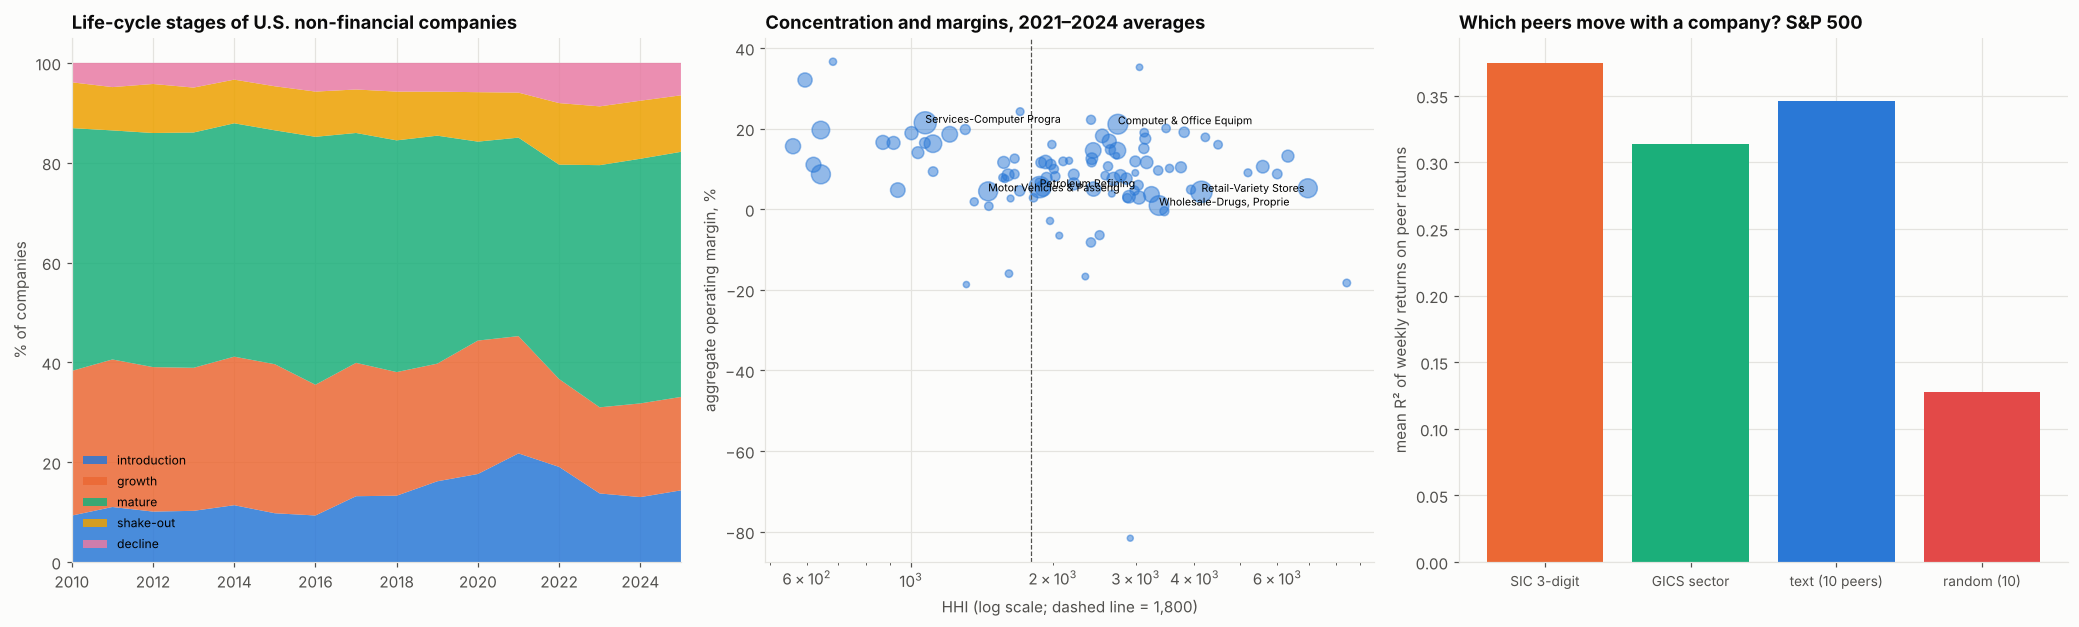

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5.8))
a = ax[0]
sh = (
    FF.dropna(subset=["stage"])
    .groupby("cy")
    .stage.value_counts(normalize=True)
    .unstack()
    .reindex(columns=STAGES)
    * 100
)
a.stackplot(
    sh.index, sh.T.to_numpy(), labels=STAGES, colors=PALETTE[:5], alpha=0.85
)
a.set_ylabel("% of companies")
a.set_title("Life-cycle stages of U.S. non-financial companies")
a.legend(fontsize=8, loc="lower left")
a.set_xlim(sh.index.min(), sh.index.max())
a = ax[1]
a.scatter(
    lat.HHI,
    lat.margin * 100,
    s=np.sqrt(lat.revenue_bn) * 6,
    color=PALETTE[0],
    alpha=0.5,
)
for _, r in lat.nlargest(6, "revenue_bn").iterrows():
    a.annotate(r.industry[:24], (r.HHI, r.margin * 100), fontsize=7)
a.set_xscale("log")
a.axvline(1800, color=INK_2, lw=0.8, ls="--")
a.set_xlabel("HHI (log scale; dashed line = 1,800)")
a.set_ylabel("aggregate operating margin, %")
a.set_title(f"Concentration and margins, {LAST_CY - 4}–{LAST_CY - 1} averages")
a = ax[2]
x = np.arange(len(PEERS))
a.bar(
    x, PEERS["mean R²"], color=[PALETTE[i] for i in (1, 2, 0, 7)][: len(PEERS)]
)
a.set_xticks(x, PEERS.index, fontsize=9)
a.set_ylabel("mean R² of weekly returns on peer returns")
a.set_title("Which peers move with a company? S&P 500")
fig.tight_layout()
save_fig(fig, "01_industry_analysis")
plt.show()

In [14]:
dash = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        f"Industry life-cycle clusters (PCA of {len(CF)} features)",
        "Next-year life-cycle stage, test 2021–2025",
    ),
)
for c in sorted(lat.cluster.unique()):
    g = lat[lat.cluster == c]
    dash.add_trace(
        go.Scatter(
            x=g.pc1,
            y=g.pc2,
            mode="markers",
            name=f"cluster {c}",
            marker=dict(color=PALETTE[c % len(PALETTE)], size=9),
            text=g.industry,
            hovertemplate="%{text}<extra></extra>",
        ),
        1,
        1,
    )
for i, m in enumerate(STG.columns):
    dash.add_trace(
        go.Bar(x=STG.index, y=STG[m], name=m, marker_color=PALETTE[i + 4]),
        1,
        2,
    )
dash.update_layout(
    height=560,
    width=1400,
    template="simple_white",
    title="Industry life cycles and competitive structure",
    barmode="group",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 9. Reading the results and limitations

**The data.** 9,330 non-financial U.S. companies filed XBRL between 2010 and 2025, giving 80,801 company-years. Of these, 116 SIC three-digit industries have at least eight companies with USD 10 million or more in revenue in some year, and 99 do in 2021–2024.

**Listed-company concentration has been rising.**
- **Median HHI:** about 1,950–2,000 across industries in 2010–2015, then 2,300–2,400 in 2024–2025.
- **Highly concentrated industries** (HHI above 1,800): 59% of industries in 2010, about two-thirds since 2016.
- **Most concentrated:** online retail (nonstore retailers, HHI ≈ 7,000, where Amazon dominates), amusement and recreation services, engines and turbines, and couriers.
- **Least concentrated:** electric utilities (HHI ≈ 560), oil and gas producers, medical instruments, electronic components and pharmaceuticals.

The utilities case shows the main caveat: each utility is a regulated local monopoly, but a national HHI of listed companies sees forty separate competitors. These are measures of listed companies under one SIC code, not of antitrust markets.

**Concentration does not go with higher or more persistent margins.**
- **Margins:** across 1,450 industry-years, the aggregate operating margin is unrelated to log HHI once years are controlled for (coefficient −0.02, t = −1.5). At company level the link is also insignificant (+0.03, t = 1.0).
- **Persistence:** unusually high or low returns on assets fade at the same speed in every concentration tercile. About 17–20% of the gap to the industry median disappears in a year (t-statistics 10–13), as Fama and French (2000) found.

On these measures, Porter's forces are not visible through concentration alone. Barriers that matter, such as regulation, intangible assets and network effects, do not show up in an SIC-level HHI.

**Life-cycle stages behave as the theory says, but they are noisy.** The Dickinson cash-flow classification puts 46% of company-years in maturity, 25% in growth, 14% in introduction, 10% in shake-out and 6% in decline. The profiles fit:

| Stage | Median growth | Median operating margin | Dividend payers |
|---|---|---|---|
| Introduction | 16% | −28% | 6% |
| Growth | 13% | +7% | 30% |
| Mature | 5% | +9% | 47% |
| Decline | 5% | −35% | 9% |

Introduction and decline firms also spend the most on R&D (median 6% and 12% of revenue): many are biotech and technology firms burning cash.

The stages are not stable. Only 66% of mature companies are mature again the next year, 44% of growth companies stay in growth, and one in three declining companies moves back to introduction (raising capital again).

**Next year's stage is hard to predict.** In 2021–2025, 47% of companies changed stage.
- **No-change forecast:** correct 53% of the time.
- **Multinomial logit:** correct 59% of the time.
- **LightGBM:** correct 58% of the time.
- **Stage changes:** among companies that did change stage, the models call the new stage correctly 27–30% of the time.

Machine learning adds about five points over persistence, and no more than a linear model. Cash-flow signs flip with one large acquisition or bond issue, which no model of fundamentals can foresee.

**Industries cluster weakly into three life-cycle groups.** The silhouette score is low (0.16 at k = 3, falling with more clusters), and k-means and a Gaussian mixture agree only partly (adjusted Rand 0.29). The groups are best read as tendencies:
- **Capital-intensive, cash-generating (4 industries, led by electric utilities):** capital expenditure of 41% of revenue, margins of 26%, 71% dividend payers, and 60% of companies classed as "growth" because they borrow to invest.
- **Mature (72 industries; refining, retail, manufacturing):** 11% margins, 57% of companies in maturity, low R&D.
- **Young and R&D-intensive (23 industries; software, pharmaceuticals, medical devices):** zero aggregate margin, R&D of 4% of revenue, 28% of companies in introduction and 13% in decline, the highest entry and exit rates, and only 18% dividend payers.

**Text-based peers explain returns about as well as SIC codes, and better than GICS sectors.** For 439 S&P 500 companies, weekly returns over three years are regressed on their peers' average return. The mean R² is:

| Peer group | Mean R² |
|---|---|
| Same SIC three-digit code | 0.38 |
| Ten nearest 10-K descriptions | 0.35 |
| Same GICS sector | 0.31 |
| Ten random members | 0.13 |

Text peers beat SIC peers for 49% of companies, a draw on average, and need no classification scheme at all. The peers make sense in most cases: Coca-Cola's closest descriptions are Monster and PepsiCo, and Uber's are DoorDash and Booking. Others show what text cannot see: Nvidia's nearest are Intel and Cadence rather than its actual competitors, and Netflix's include video-game publishers. Clusters of the descriptions agree only loosely with GICS sectors (adjusted Rand 0.18) or SIC two-digit codes (0.23); the two official schemes do not agree much with each other either (0.26).

**Limits.**
- Listed U.S. companies only: concentration ignores private firms, imports and segment-level activity. SIC is the company's primary code, last updated by the SEC.
- Entry and exit are listings and delistings in XBRL data, not new competitors.
- The text analysis uses the first 40,000 characters of Item 1 and a small embedding model. Peers are measured on today's members and recent returns.

In [15]:
IY.to_csv(OUT_DIR / "industry_year_structure.csv", index=False)
lat.drop(columns=["pc1", "pc2"]).to_csv(
    OUT_DIR / "industry_profiles_latest.csv", index=False
)
CL.to_csv(OUT_DIR / "industry_clusters.csv")
STG.to_csv(OUT_DIR / "stage_forecast_test.csv")
TM.to_csv(OUT_DIR / "stage_transition_matrix.csv")
PEERS.to_csv(OUT_DIR / "peer_definitions_r2.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_industry_analysis.png, dashboard.html, dashboard.png, industry_clusters.csv, industry_profiles_latest.csv, industry_year_structure.csv, peer_definitions_r2.csv, stage_forecast_test.csv, stage_transition_matrix.csv


## References

- U.S. Securities and Exchange Commission. XBRL frames API, Financial Statement Data Sets and EDGAR submissions API. https://www.sec.gov/search-filings/edgar-application-programming-interfaces
- U.S. Securities and Exchange Commission. Standard Industrial Classification (SIC) code list. https://www.sec.gov/search-filings/standard-industrial-classification-sic-code-list
- BlackRock iShares. Core S&P 500 ETF (IVV) holdings. https://www.ishares.com/
- Yahoo Finance. Weekly prices. https://finance.yahoo.com/
- CFA Institute. CFA Program Level I curriculum, Equity Investments: Industry and Company Analysis.
- U.S. Department of Justice & Federal Trade Commission. (2023). *Merger Guidelines*.
- Porter, M. E. (2008). The five competitive forces that shape strategy. *Harvard Business Review*, 86(1), 78–93.
- Dickinson, V. (2011). Cash flow patterns as a proxy for firm life cycle. *The Accounting Review*, 86(6), 1969–1994.
- Fama, E. F., & French, K. R. (2000). Forecasting profitability and earnings. *Journal of Business*, 73(2), 161–175.
- Hoberg, G., & Phillips, G. (2016). Text-based network industries and endogenous product differentiation. *Journal of Political Economy*, 124(5), 1423–1465.
- Bhojraj, S., Lee, C. M. C., & Oler, D. K. (2003). What's my line? A comparison of industry classification schemes for capital market research. *Journal of Accounting Research*, 41(5), 745–774.
- Reimers, N., & Gurevych, I. (2019). Sentence-BERT: Sentence embeddings using Siamese BERT-networks. *Proceedings of EMNLP-IJCNLP*, 3982–3992.